# Exploratory data analysis

What the lab (PlantVillage) and field (PlantDoc) data look like for the 10 classes in [class-mapping.md](../docs/class-mapping.md), and how they differ. Raw file checks are in [data-audit.md](../docs/data-audit.md) and are not repeated here.

Needs `data/` built first: `scripts/download_data.py`, `audit_data.py`, `make_splits.py`, `build_cache.py`. Figures are written to `results/figures/eda/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from leafshift.data import REPO_ROOT, SPLITS, load_cache_meta

FIGURES = REPO_ROOT / "results" / "figures" / "eda"
LAB_SPLITS = ("train", "val", "test")
FIELD_SPLITS = ("field_finetune", "field_test")
LAB, FIELD = "#2a78d6", "#eb6834"
plt.rcParams.update({"font.size": 9, "savefig.dpi": 200, "savefig.bbox": "tight"})

meta = load_cache_meta()
CLASSES = meta["classes"]
splits = pd.read_csv(REPO_ROOT / "data" / "splits" / "splits.csv")
print(f"{len(CLASSES)} classes, cache size {meta['size']}px")
print(meta["counts"])

10 classes, cache size 224px
{'train': 11944, 'val': 2561, 'test': 2561, 'field_finetune': 100, 'field_test': 601}


## 1. Class distribution

Images per class in each split. Lab and field are drawn on separate axes because they differ by two orders of magnitude.

In [2]:
def short(cls):
    crop, disease = cls.split("___")
    disease = disease.replace("Tomato_", "").replace("_", " ")
    return f"{crop} {disease.lower()}" if disease != "healthy" else f"{crop} healthy"

counts = pd.crosstab(splits["class"], splits["split"]).reindex(index=CLASSES, columns=list(SPLITS))
counts["lab"] = counts[list(LAB_SPLITS)].sum(axis=1)
counts["field"] = counts[list(FIELD_SPLITS)].sum(axis=1)
counts.index = counts.index.map(short)
counts.loc["Total"] = counts.sum()
counts

split,train,val,test,field_finetune,field_test,lab,field
class,,,,,,,
Potato early blight,700,150,150,10,52,1000,62
Potato late blight,700,150,150,10,77,1000,87
Tomato bacterial spot,1489,319,319,10,45,2127,55
Tomato early blight,700,150,150,10,59,1000,69
Tomato late blight,1331,285,285,10,88,1901,98
Tomato leaf mold,666,143,143,10,58,952,68
Tomato septoria leaf spot,1239,266,266,10,107,1771,117
Tomato yellow leaf curl virus,3749,804,804,10,49,5357,59
Tomato mosaic virus,261,56,56,10,31,373,41


In [3]:
per_class = counts.drop(index="Total")
for name in ("train", "field_test"):
    col = per_class[name]
    print(f"{name:>10}: smallest {col.min()} ({col.idxmin()}), largest {col.max()} ({col.idxmax()}), "
          f"ratio {col.max() / col.min():.1f}x")

     train: smallest 261 (Tomato mosaic virus), largest 3749 (Tomato yellow leaf curl virus), ratio 14.4x
field_test: smallest 31 (Tomato mosaic virus), largest 107 (Tomato septoria leaf spot), ratio 3.5x


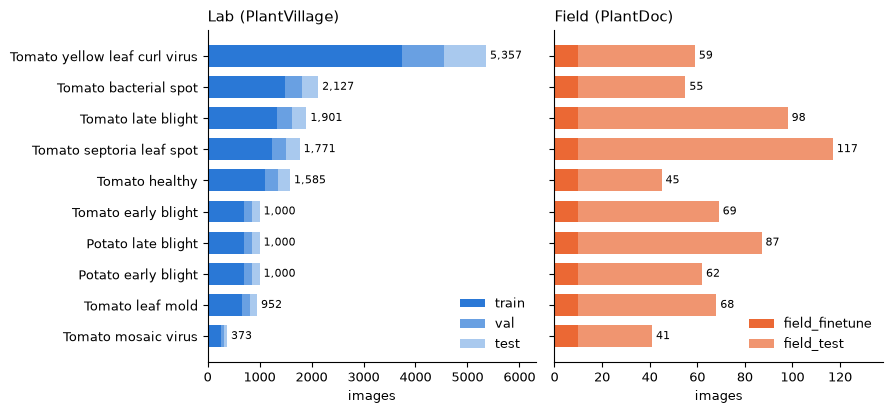

In [4]:
order = per_class.sort_values("lab").index
y = np.arange(len(order))
fig, (ax_lab, ax_field) = plt.subplots(1, 2, figsize=(9, 4.2), sharey=True)

for ax, parts, colour, title in (
    (ax_lab, LAB_SPLITS, LAB, "Lab (PlantVillage)"),
    (ax_field, FIELD_SPLITS, FIELD, "Field (PlantDoc)"),
):
    left = np.zeros(len(order))
    for i, part in enumerate(parts):
        values = per_class.loc[order, part].to_numpy()
        ax.barh(y, values, left=left, color=colour, alpha=1 - 0.3 * i, label=part, height=0.7)
        left += values
    for yi, total in zip(y, left):
        ax.text(total, yi, f" {int(total):,}", va="center", fontsize=8)
    ax.set_title(title, loc="left")
    ax.set_xlabel("images")
    ax.set_xlim(0, left.max() * 1.18)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="lower right")

ax_lab.set_yticks(y, order)
fig.tight_layout()
FIGURES.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURES / "class_distribution.png")
plt.show()

## 2. Raw image properties

Size, format and colour mode of the original files, before caching, for the images this project uses. Taken from `data/audit/images.csv` (written by `scripts/audit_data.py`), so no image is reopened here. Width and height are as stored, before EXIF rotation; this does not affect the aspect ratio.

In [5]:
audit = pd.read_csv(REPO_ROOT / "data" / "audit" / "images.csv",
                    usecols=["path", "bytes", "format", "width", "height", "mode"])
raw = splits[["path", "dataset", "split"]].merge(audit, on="path", how="left", validate="one_to_one")
assert raw["width"].notna().all(), "an image in splits.csv is missing from the audit"

raw["domain"] = np.where(raw["split"].isin(LAB_SPLITS), "lab", "field")
raw["size"] = raw["width"].astype(str) + "x" + raw["height"].astype(str)
raw["long_side"] = raw[["width", "height"]].max(axis=1)
raw["short_side"] = raw[["width", "height"]].min(axis=1)
raw["padding"] = 1 - raw["short_side"] / raw["long_side"]  # share of the square canvas filled with padding

raw.groupby("domain").agg(
    images=("path", "size"),
    distinct_sizes=("size", "nunique"),
    median_long_side=("long_side", "median"),
    min_short_side=("short_side", "min"),
    max_long_side=("long_side", "max"),
    median_kb=("bytes", lambda b: round(b.median() / 1024)),
    padded=("padding", lambda p: f"{(p > 0).mean():.0%}"),
).reindex(["lab", "field"])

,images,distinct_sizes,median_long_side,min_short_side,max_long_side,median_kb,padded
domain,,,,,,,
lab,17066,1,256.0,256,256,15,0%
field,701,491,768.0,69,6000,117,96%


In [6]:
pd.crosstab([raw["format"], raw["mode"]], raw["domain"]).reindex(columns=["lab", "field"], fill_value=0)

,domain,lab,field
format,mode,,
JPEG,RGB,17066,700
MPO,RGB,0,1


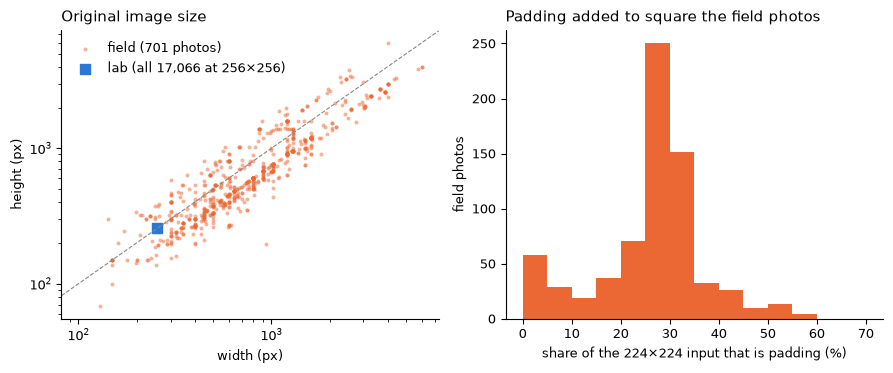

field padding: median 25%, over a quarter of the canvas in 43% of photos


In [7]:
field = raw[raw["domain"] == "field"]
fig, (ax_size, ax_pad) = plt.subplots(1, 2, figsize=(9, 3.8))

ax_size.scatter(field["width"], field["height"], s=8, color=FIELD, alpha=0.5, linewidths=0,
                label=f"field ({len(field)} photos)")
ax_size.scatter([256], [256], s=60, color=LAB, marker="s",
                label=f"lab (all {(raw['domain'] == 'lab').sum():,} at 256×256)")
ax_size.axline((100, 100), slope=1, color="#898781", lw=0.8, ls="--")
ax_size.set(xscale="log", yscale="log", xlabel="width (px)", ylabel="height (px)")
ax_size.set_title("Original image size", loc="left")
ax_size.legend(frameon=False, loc="upper left")

ax_pad.hist(field["padding"] * 100, bins=np.arange(0, 75, 5), color=FIELD)
ax_pad.set(xlabel="share of the 224×224 input that is padding (%)", ylabel="field photos")
ax_pad.set_title("Padding added to square the field photos", loc="left")

for ax in (ax_size, ax_pad):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "image_sizes.png")
plt.show()

print(f"field padding: median {field['padding'].median():.0%}, "
      f"over a quarter of the canvas in {(field['padding'] > 0.25).mean():.0%} of photos")

## 3. Colour statistics

Colour of the 224×224 cached images the models actually see, lab test against field test. Pixels exactly equal to the pad colour are left out, so padding does not count as field colour. Hue, saturation and brightness come from converting RGB to HSV. Hue is only counted for pixels with at least 20% saturation: on near-grey pixels, such as the lab background, hue is mostly rounding noise.

In [8]:
from matplotlib.colors import rgb_to_hsv

CACHE = REPO_ROOT / "data" / "cache"
PAD = np.array(meta["pad_colour"], dtype=np.uint8)
BINS = 64
MIN_SAT_FOR_HUE = 0.2


def colour_stats(split, batch=128):
    images = np.load(CACHE / f"{split}.npy", mmap_mode="r")
    rgb_sum, rgb_sq, n_pixels, n_pad, n_coloured = np.zeros(3), np.zeros(3), 0, 0, 0
    hists = {c: np.zeros(BINS) for c in ("hue", "saturation", "brightness")}
    for start in range(0, len(images), batch):
        pixels = np.asarray(images[start:start + batch]).reshape(-1, 3)
        keep = ~(pixels == PAD).all(axis=1)
        n_pad += (~keep).sum()
        pixels = pixels[keep].astype(np.float64) / 255
        rgb_sum += pixels.sum(axis=0)
        rgb_sq += (pixels ** 2).sum(axis=0)
        n_pixels += len(pixels)
        hsv = rgb_to_hsv(pixels)
        coloured = hsv[:, 1] >= MIN_SAT_FOR_HUE
        hists["hue"] += np.histogram(hsv[coloured, 0], bins=BINS, range=(0, 1))[0]
        hists["saturation"] += np.histogram(hsv[:, 1], bins=BINS, range=(0, 1))[0]
        hists["brightness"] += np.histogram(hsv[:, 2], bins=BINS, range=(0, 1))[0]
        n_coloured += coloured.sum()
    mean = rgb_sum / n_pixels
    std = np.sqrt(rgb_sq / n_pixels - mean ** 2)
    return {"mean": mean, "std": std, "pad_share": n_pad / (n_pad + n_pixels),
            "hue_share": n_coloured / n_pixels,
            "hists": {c: h / h.sum() for c, h in hists.items()}}


stats = {"lab": colour_stats("test"), "field": colour_stats("field_test")}

pd.DataFrame({
    domain: {**{f"{ch} mean": s["mean"][i] for i, ch in enumerate("RGB")},
             **{f"{ch} std": s["std"][i] for i, ch in enumerate("RGB")},
             "pad pixels left out": s["pad_share"],
             "pixels with a hue counted": s["hue_share"]}
    for domain, s in stats.items()
}).round(3)

,lab,field
R mean,0.449,0.425
G mean,0.468,0.509
B mean,0.398,0.344
R std,0.181,0.246
G std,0.161,0.242
B std,0.198,0.252
pad pixels left out,0.000,0.254
pixels with a hue counted,0.436,0.813


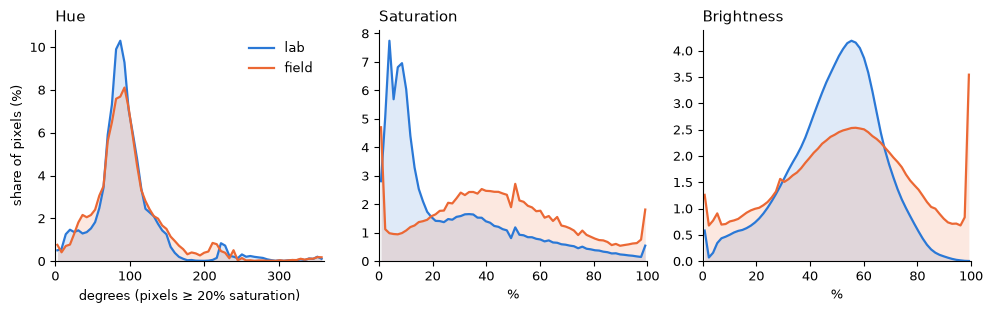

In [9]:
centres = (np.arange(BINS) + 0.5) / BINS
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, (channel, scale, unit) in zip(axes, (("hue", 360, "degrees (pixels ≥ 20% saturation)"), ("saturation", 100, "%"), ("brightness", 100, "%"))):
    for domain, colour in (("lab", LAB), ("field", FIELD)):
        h = stats[domain]["hists"][channel]
        ax.plot(centres * scale, h * 100, color=colour, label=domain, lw=1.6)
        ax.fill_between(centres * scale, h * 100, color=colour, alpha=0.15, lw=0)
    ax.set_title(channel.capitalize(), loc="left")
    ax.set_xlabel(unit)
    ax.set_xlim(0, scale)
    ax.set_ylim(bottom=0)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("share of pixels (%)")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "colour_distributions.png")
plt.show()

## 4. Lab and field images side by side

Randomly chosen images from the lab test and field test splits, as the models see them: 224×224 from the cache, field photos padded to square. The seed fixes the choice, so the figure is the same each run.

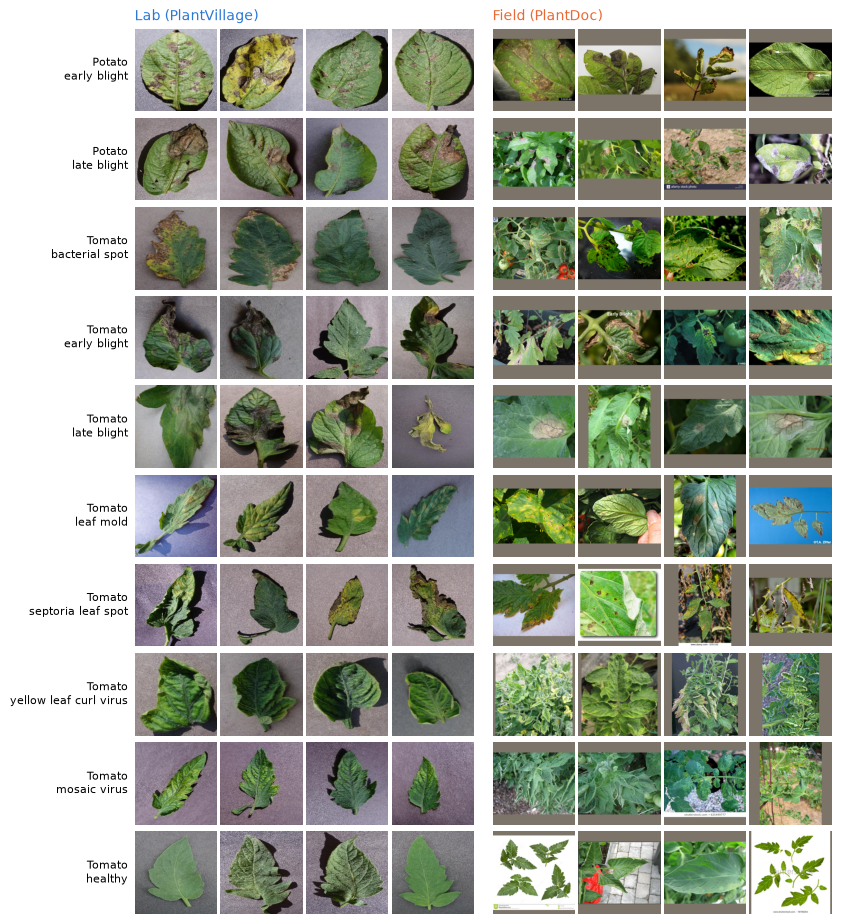

In [10]:
PER_SIDE = 4
rng = np.random.default_rng(0)
picked = {}
for domain, split in (("lab", "test"), ("field", "field_test")):
    index = pd.read_csv(CACHE / f"{split}.csv")
    images = np.load(CACHE / f"{split}.npy", mmap_mode="r")
    picked[domain] = {
        cls: [np.asarray(images[row]) for row in rng.choice(index.loc[index["class"] == cls, "row"], PER_SIDE, replace=False)]
        for cls in CLASSES
    }

fig, axes = plt.subplots(len(CLASSES), 2 * PER_SIDE + 1, figsize=(9, 11.5),
                         gridspec_kw={"width_ratios": [1] * PER_SIDE + [0.15] + [1] * PER_SIDE,
                                      "wspace": 0.04, "hspace": 0.08})
for r, cls in enumerate(CLASSES):
    tiles = picked["lab"][cls] + [None] + picked["field"][cls]
    for c, tile in enumerate(tiles):
        ax = axes[r, c]
        ax.axis("off")
        if tile is not None:
            ax.imshow(tile)
    axes[r, 0].text(-0.08, 0.5, short(cls).replace(" ", "\n", 1), transform=axes[r, 0].transAxes,
                    ha="right", va="center", fontsize=8)
axes[0, 0].set_title("Lab (PlantVillage)", loc="left", color=LAB, fontsize=10)
axes[0, PER_SIDE + 1].set_title("Field (PlantDoc)", loc="left", color=FIELD, fontsize=10)
for ax in axes[0]:
    ax.title.set_position((0, 1.05))
fig.savefig(FIGURES / "lab_vs_field_samples.png", dpi=150)
plt.show()

## 5. Takeaways

1. **Lab classes are unbalanced; field classes are unbalanced differently.** In lab training, yellow leaf curl virus has 14.4× as many images as mosaic virus (3,749 against 261). In the field test the ratio is 3.5× (107 Septoria against 31 mosaic), and yellow leaf curl falls from the largest class to the middle. Accuracy alone would mostly reflect the large classes, so every model is also scored by macro F1, which weights the 10 classes equally.
2. **Two field classes are small.** Mosaic virus (31) and healthy tomato (35) have the fewest field test photos, so one error moves their per-class accuracy by about 3 points. Their per-class results are reported with that caveat.
3. **Image format alone separates the domains.** Every lab image is 256×256; the field photos come in 491 sizes, from a 69 px short side to a 6,000 px long side. 96% of field photos needed padding to become square (median 25% of the input), and no lab image did. Padding keeps every lesion in frame, but it is a difference between the test sets that the leaves did not cause. 13 field photos were smaller than 224 px and had to be enlarged.
4. **The leaves are similar in colour; what surrounds them is not.** On coloured pixels the hue curves almost coincide, peaking near 90° (yellow-green). The difference is in saturation and brightness: 56% of lab pixels are near-grey background, against 19% in the field, and field photos have a wider spread of brightness, including overexposed white. A colour-histogram model trained on lab images learns that grey background as part of every class, which is a likely reason Baseline A falls to 16.0% on field photos.
5. **Field photos show different scenes, not just different lighting.** A lab image is one detached leaf, centred on a plain background. A field photo is often a whole plant or a section of canopy, against soil, sky, hands or white, and some carry watermarks or captions. A model has to find the diseased leaf before it can name the disease, which is what pre-training, augmentation and the 10-photo fine-tuning slice are meant to help with.